In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/README.dataset.txt
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/data.yaml
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/distal-humerus-fracture-1_jpg.rf.831cb137cfcbde1079f86abd5f5f2867.jpg
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_1000_png.rf.a53c5e186c03961bf88075c6e3e94cf6.jpg
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_1015_png.rf.9181f8eb07451331e22381bacb3a5bd2.jpg
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_1035_png.rf.d7493a5653bc3628f7a1b1ec0eb5de85.jpg
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_1044_png.rf.1e17d3a8637036ef4b3e1c5d0b88011f.jpg
/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_1084_png.rf.d9da08b77872f6b4282f2700d216b9b3.jpg
/kaggle/input/datasets/justin

In [4]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 44.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [5]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
import shutil
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


# 训练骨折检测模型

In [6]:
model = YOLO('yolo11n.pt')

In [7]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/data.yaml \
    epochs = 30 \
    batch  = 64 \
    device = 0,1
    

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=tr

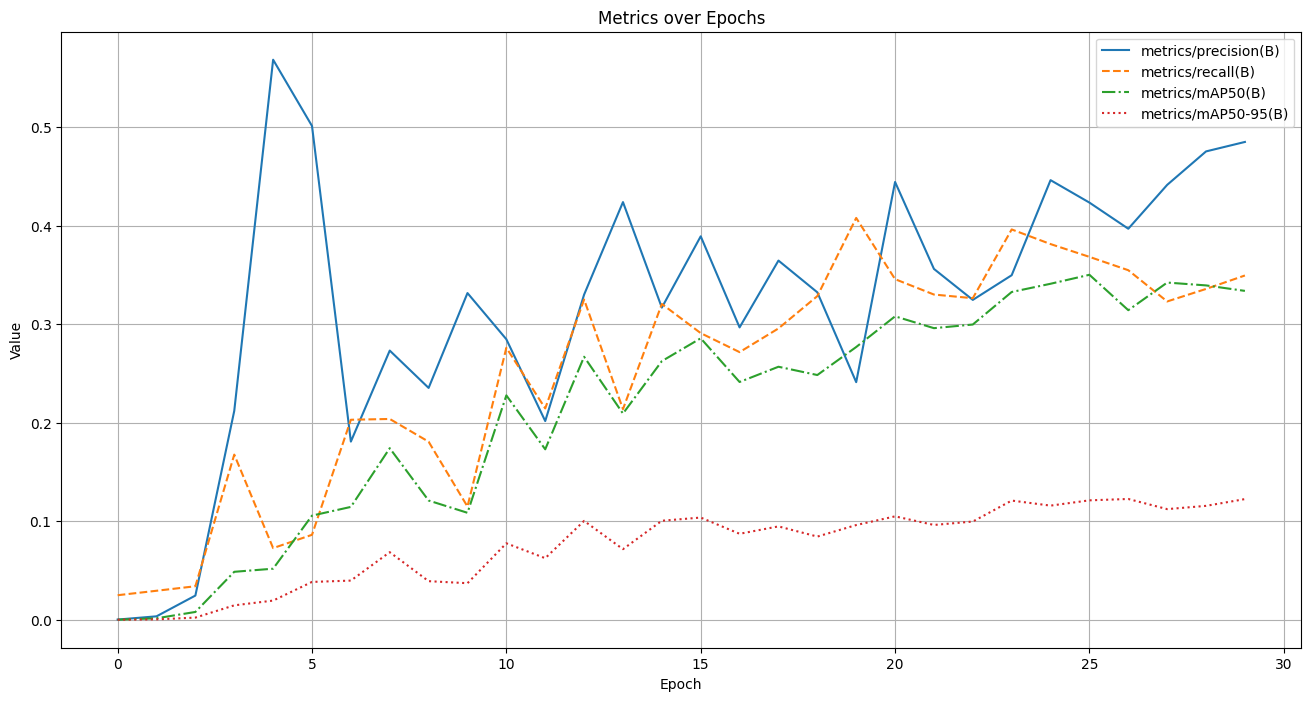

In [10]:
# 从指定路径读取训练结果的 csv 文件到 DataFrame
df = pd.read_csv('/kaggle/working/runs/detect/train/results.csv')

# 定义需要绘制的评估指标列表和线型列表
metrics_to_plot = [
    'metrics/precision(B)',
    'metrics/recall(B)',
    'metrics/mAP50(B)',
    'metrics/mAP50-95(B)'
]
line_styles = ['-', '--', '-.', ':']

# 检查 DataFrame 中是否包含所有需要绘制的指标并绘制图形
if all(col in df.columns for col in metrics_to_plot):
    plt.figure(figsize = (16, 8))
    for i, metric in enumerate(metrics_to_plot):
        plt.plot(df.index, df[metric], label = metric, linestyle = line_styles[i % len(line_styles)])
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title('Metrics over Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Error: Some specified metrics are not present in the DataFrame.")

In [11]:
def display_images(image1_path, image2_path):
    # 使用 OpenCV 读取两张图片
    image1 = cv2.imread(image1_path)
    image2 = cv2.imread(image2_path)

    # 将图片颜色空间从 BGR 转换为 RGB
    image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
    image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

    plt.figure(figsize = (15, 10))

    plt.subplot(1, 2, 1)
    plt.imshow(image1)
    plt.title('val label')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(image2)
    plt.title('val predict')
    plt.axis('off')

    plt.show()

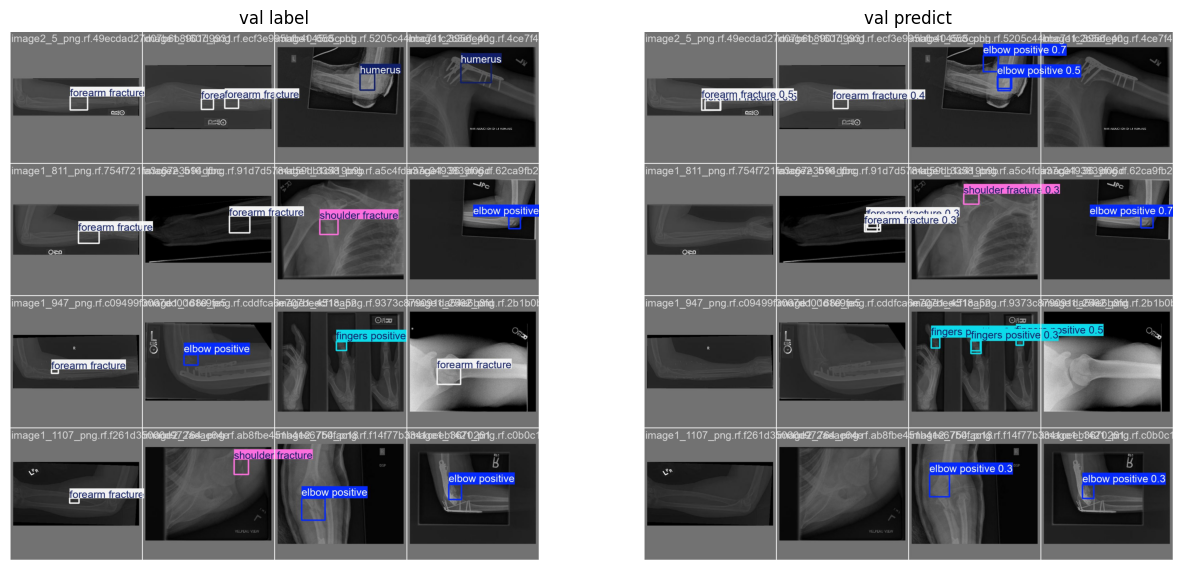

In [12]:
image1_path = '/kaggle/working/runs/detect/train/val_batch0_labels.jpg'
image2_path = '/kaggle/working/runs/detect/train/val_batch0_pred.jpg'
display_images(image1_path, image2_path)

In [13]:
# 加载训练好的最优模型
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
# 模型验证
metrics = model.val(data='/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/data.yaml')

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 22.7±8.2 MB/s, size: 10.9 KB)
val: Scanning /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/valid/labels... 173 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 173/173 665.9it/s 0.3s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 4.4it/s 2.5s0.1s
                   all        173        204      0.377      0.358      0.319       0.12
        elbow positive         28         29      0.166      0.241     0.0807       0.02
      fingers positive         41         48      0.257      0.292      0.164     0.0455
      forearm fracture         37       

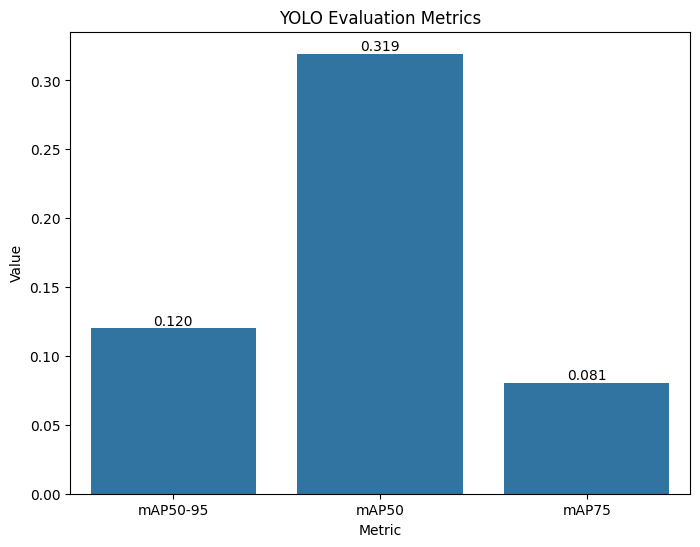

In [15]:
%matplotlib inline
# Create the barplot
ax = sns.barplot(
    x = ['mAP50-95', 'mAP50', 'mAP75'],
    y = [metrics.box.map, metrics.box.map50, metrics.box.map75]
)

ax.set_title('YOLO Evaluation Metrics')
ax.set_xlabel('Metric')
ax.set_ylabel('Value')

fig = plt.gcf()
fig.set_size_inches(8, 6)

for p in ax.patches:
    ax.annotate(
        '{:.3f}'.format(p.get_height()), 
        (p.get_x() + p.get_width() / 2, p.get_height()), 
        ha = 'center', va = 'bottom'
    )

plt.show()


image 1/1 /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_848_png.rf.029e1130bf23b22edbf687ed6b1902ed.jpg: 640x224 1 forearm fracture, 8.4ms
Speed: 5.0ms preprocess, 8.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 224)

image 1/1 /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_6234_png.rf.564f9903c116204416868f0a2273e6ba.jpg: 640x576 (no detections), 51.4ms
Speed: 2.4ms preprocess, 51.4ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 576)

image 1/1 /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_4007_png.rf.5c5b46eb5afec1aecfd8ec0119476889.jpg: 640x160 1 fingers positive, 48.2ms
Speed: 1.5ms preprocess, 48.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 160)

image 1/1 /kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets/test/images/image1_4498_png.rf.36adec7c0d9bacf95faf5c87d28dfbe7.jpg: 640x608 (no detections), 62.7m

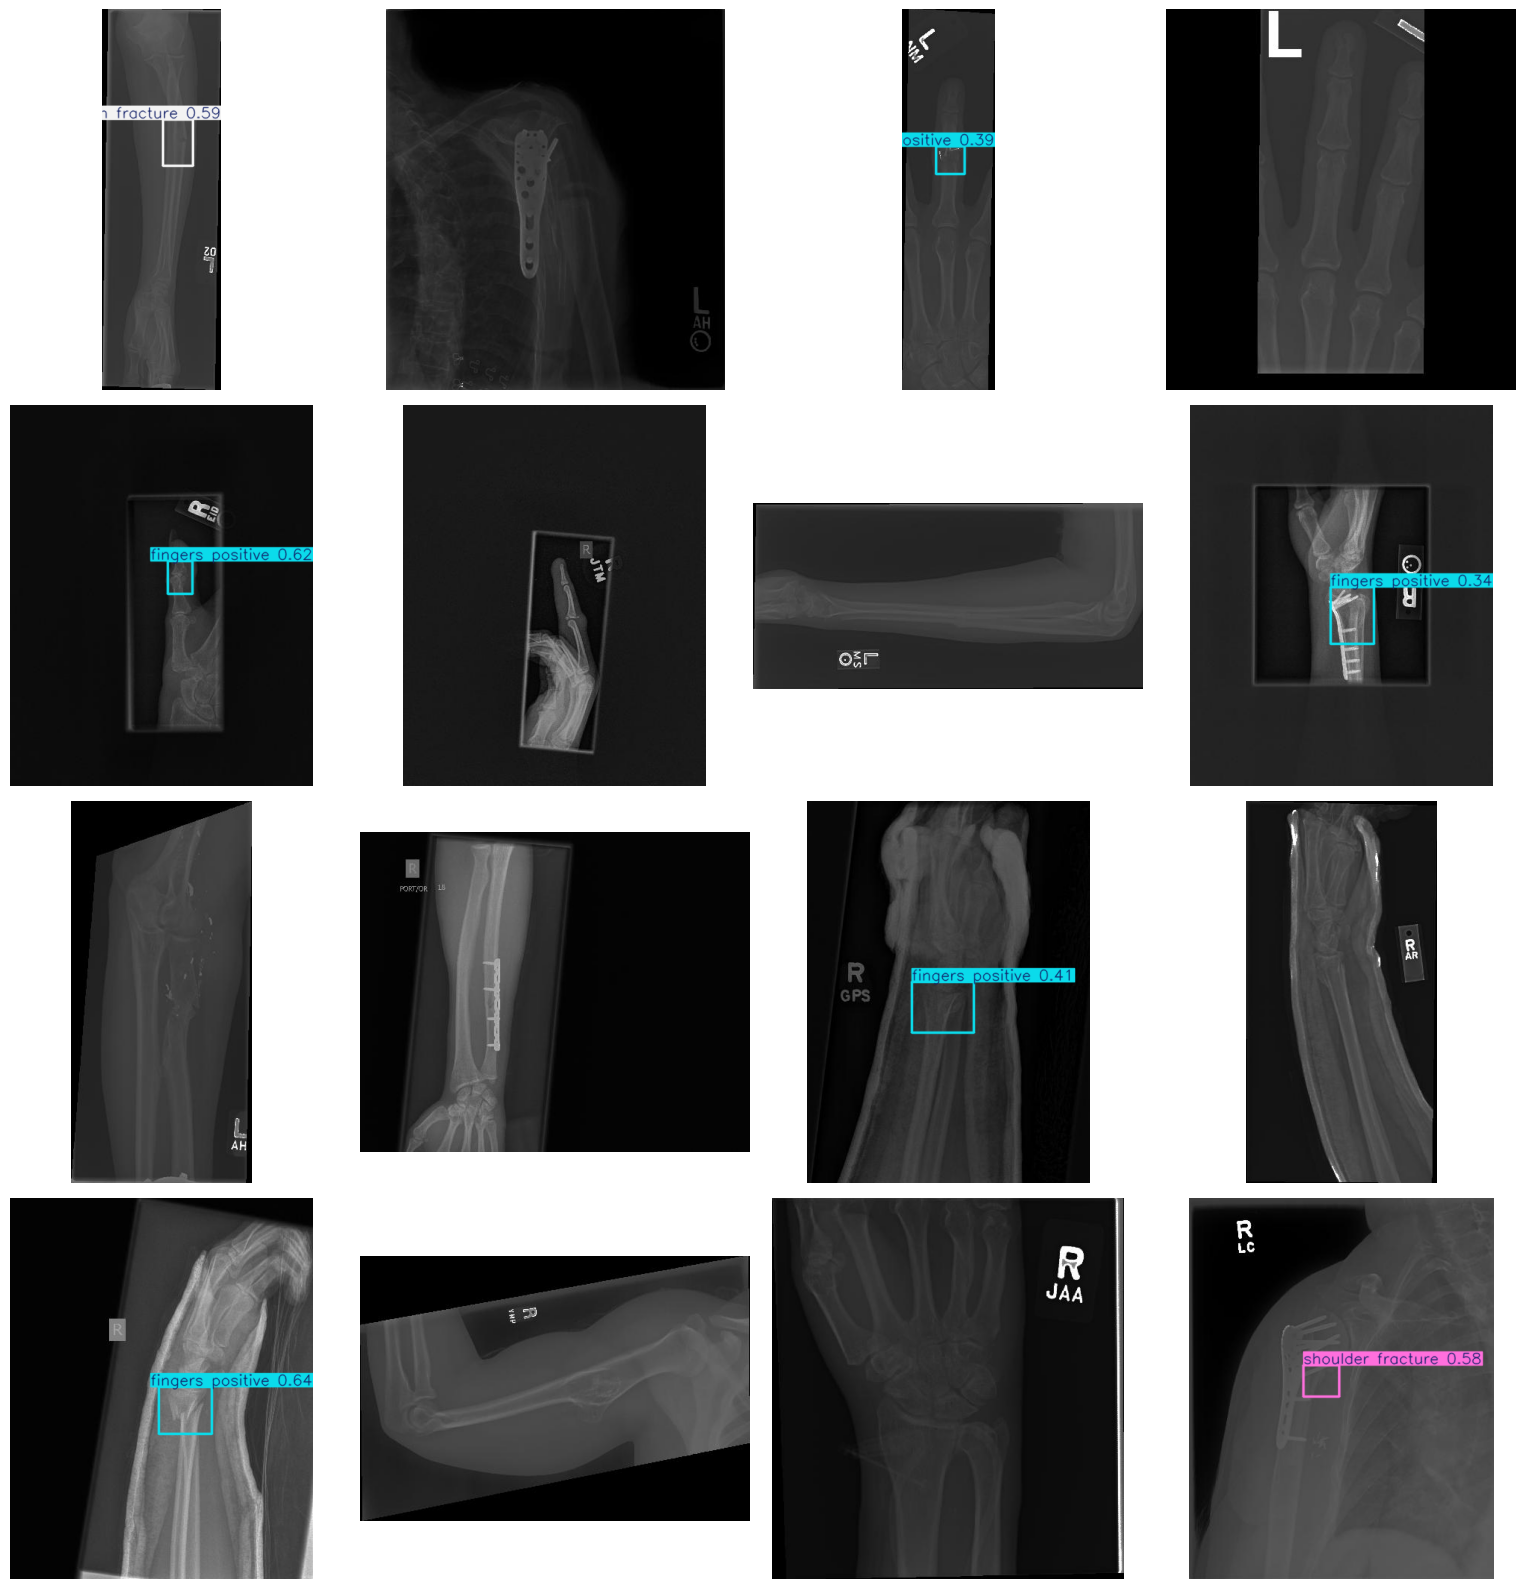

In [18]:
# 定义测试图片目录的路径
datasets_path = '/kaggle/input/datasets/justinwshj/dataset-bone-fracture/datasets'
test_img_dir = os.path.join(datasets_path, 'test/images')

def pred_images_show(images = test_img_dir, num_sample = 16):
    # 获取图片目录中的所有图片文件名
    image_files = os.listdir(images)
    # 随机选择指定数量的图片文件
    rand_imgs = random.sample(image_files, num_sample)

    # 构建一个 4 * 4 的图布局，用于显示图片
    fig, axes = plt.subplots(4, 4, figsize = (16, 16))
    # 遍历每个样本图片
    for i in range(num_sample):
        # 获取当前图片文件名
        image = rand_imgs[i]
        # 确定当前图片在图布局中的位置
        ax = axes[i // 4, i % 4]
        # 使用模型对当前图片进行预测
        result_predict = model.predict(source = os.path.join(images, image))
        # 将预测结果的图片显示在子图中
        ax.imshow(cv2.cvtColor(result_predict[0].plot(), cv2.COLOR_BGR2RGB))
        # 关闭子图的坐标轴
        ax.axis('off')
    # 调整图布局，使其紧凑
    plt.tight_layout()
    # 显示图片
    plt.show()

# 调用函数显示预测图片
pred_images_show()

In [19]:
!zip -q -r results.zip /kaggle/working/*